# HASA: heterogeneity-aware subnet allocation

**HASA: Subnet Allocation for Compute-Constrained Model-Heterogeneous Federated Learning**
Amir Hossein Shahdadian, Ahmed M. Abdelmoniem, Mahdi Taheri, Samira Nazari, Christian Herglotz · IEEE EDGE 2026
[Paper](https://arxiv.org/abs/2606.07621) · [Code](https://github.com/Reliable-and-Secure-Systems/HASA)

In model-heterogeneous federated learning, every client trains a subnet of one shared model, sized to what the client can afford. HASA decides how wide each subnet should be. It measures how far each client's training data is from the data of the whole federation, gives the wider subnets to the clients that are most different, and keeps the total compute budget fixed.

This notebook runs the article-title experiment of the paper from start to finish:

1. set up the federation: seven Medium publications, one client each;
2. score how different each client's data is;
3. turn the scores into subnet widths under a fixed budget;
4. see what a width means inside the model;
5. train the federated model with HASA widths and with uniform widths, over the paper's ten seeds;
6. compare the two, overall and client by client.

The first steps take seconds. Training is the slow part: twenty federated runs of a few minutes each on a GPU, so choose a GPU runtime in Colab (*Runtime → Change runtime type → T4 GPU*).

## 1. Setup

In [1]:
import os
if os.path.exists("../hasa"):          # opened from notebooks/ inside the repository
    os.chdir("..")
elif not os.path.exists("hasa"):       # Google Colab: fetch the code
    !git clone -q https://github.com/Reliable-and-Secure-Systems/HASA.git
    os.chdir("HASA")
!pip -q install --disable-pip-version-check demoji==1.1.0

import time
import numpy as np, pandas as pd
from hasa import load_benchmark, heterogeneity_scores, hasa_allocation, run_policy, get_device, device_name
from hasa.report import summary_table, plot_results, per_client_table, plot_client_gains

device = get_device()
print("running on", device_name(device))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 kB 2.3 MB/s eta 0:00:00
running on Tesla T4


## 2. Seven publications, seven clients

Each client is one Medium publication. Its articles are split 70/10/20 into training, validation and test articles, and every title becomes a set of next-word prediction examples. The clients are very unequal in size, as in most real federations.

In [2]:
bench = load_benchmark("data/medium_data.csv", verbose=False)

clients = pd.DataFrame({"articles": [c.n_articles for c in bench.clients],
                        "training examples": bench.client_data_sizes,
                        "test examples": [c.sizes["test"] for c in bench.clients]},
                       index=pd.Index(bench.client_names, name="client"))
clients.style.bar(subset=["training examples"], color="#E9C9D5")

,articles,training examples,test examples
client,,,
The Startup,2686,13215,3785
Towards Data Science,1298,6054,1763
Data Driven Investor,689,3354,971
UX Collective,503,2570,753
The Writing Cooperative,357,1719,499
Better Marketing,216,1195,349
Better Humans,25,141,55


## 3. How different is each client?

HASA compares the word distribution of each client's training titles with the pooled distribution of the whole federation, using the Jensen-Shannon divergence. Only training data is used. A higher score means the client's data is further from the mix.

In [3]:
scores = heterogeneity_scores(bench)
clients["heterogeneity (JSD)"] = scores

(clients[["training examples", "heterogeneity (JSD)"]].style
    .bar(subset=["heterogeneity (JSD)"], color="#E9C9D5")
    .format({"heterogeneity (JSD)": "{:.3f}"}))

,training examples,heterogeneity (JSD)
client,,
The Startup,13215,0.043
Towards Data Science,6054,0.110
Data Driven Investor,3354,0.096
UX Collective,2570,0.120
The Writing Cooperative,1719,0.121
Better Marketing,1195,0.105
Better Humans,141,0.192


## 4. From scores to subnet widths

This is Algorithm 1 of the paper. The scores are ranked, and the ranks are mapped linearly to widths between 0.2 and 0.8. The widths are then rescaled so that their size-weighted mean equals the compute budget B = 0.5, and clipped to the bounds. Uniform allocation gives every client 0.5, so both allocations cost the same compute.

In [4]:
n = np.array(bench.client_data_sizes, dtype=float)
p = n / n.sum()                                                     # client weights n_i / N
r = 0.2 + 0.6 * np.argsort(np.argsort(scores)) / (len(scores) - 1)  # rank, then map to [0.2, 0.8]
for _ in range(2):
    r = np.clip(r * 0.5 / (p @ r), 0.2, 0.8)                        # meet the budget, stay in bounds
assert np.allclose(r, hasa_allocation(bench.client_data_sizes, scores))   # same as the library

clients["HASA width (%)"] = 100 * r
print(f"size-weighted mean width: HASA {p @ r:.3f}, uniform 0.500 (budget 0.5)")
(clients[["training examples", "heterogeneity (JSD)", "HASA width (%)"]].style
    .bar(subset=["HASA width (%)"], color="#E9C9D5", vmin=0, vmax=100)
    .format({"heterogeneity (JSD)": "{:.3f}", "HASA width (%)": "{:.1f}"}))

size-weighted mean width: HASA 0.496, uniform 0.500 (budget 0.5)


,training examples,heterogeneity (JSD),HASA width (%)
client,,,
The Startup,13215,0.043,29.2
Towards Data Science,6054,0.110,73.1
Data Driven Investor,3354,0.096,43.8
UX Collective,2570,0.120,80.0
The Writing Cooperative,1719,0.121,80.0
Better Marketing,1195,0.105,58.4
Better Humans,141,0.192,80.0


## 5. What a width means inside the model

All clients share one LSTM with 128-dimensional embeddings and 256 hidden units. A client with width r trains only the first ⌊256·r⌋ hidden units. The function below cuts those units out of the shared weights (their gate rows, their recurrent weights and their output columns) and runs the LSTM on the slices, so a narrow subnet really computes less.

In [5]:
import inspect
from hasa.model import forward_subnet_with_indices
print(inspect.getsource(forward_subnet_with_indices))

units = [max(16, int(256 * w)) for w in r]
clients["hidden units"] = units
clients["LSTM compute (%)"] = [100 * (4*a*128 + 4*a*a) / (4*256*128 + 4*256*256) for a in units]
clients[["HASA width (%)", "hidden units", "LSTM compute (%)"]].style.format("{:.1f}", subset=["HASA width (%)", "LSTM compute (%)"])

def forward_subnet_with_indices(model, x, active_idx_list, hidden_dim):
    """LSTM forward pass that uses only the hidden units in `active_idx_list`
    (a prefix for HASA / HeteroFL, a random or rolling set for the other baselines).

    The gate rows, the recurrent block and the output columns of those units are cut out
    of the shared weights, and PyTorch's LSTM kernel runs on the slices: the subnet computes
    less, and its gradients flow back into the shared weights."""
    idx = torch.as_tensor(active_idx_list, device=x.device, dtype=torch.long)
    gates = torch.cat([idx + k * hidden_dim for k in range(4)])   # input, forget, cell, output gates
    lstm = model.lstm
    weights = {"weight_ih_l0": lstm.weight_ih_l0[gates],
               "weight_hh_l0": lstm.weight_hh_l0[gates][:, idx],
               "bias_ih_l0": lstm.bias_ih_l0[gates],
               "bias_hh_l0": lstm.bias_hh_l0[gates]}
    h0 = torch.zeros(1, x.size(0), len(idx), device=x.device)
    out, _ = functional_

,HASA width (%),hidden units,LSTM compute (%)
client,,,
The Startup,29.2,74,15.2
Towards Data Science,73.1,187,59.9
Data Driven Investor,43.8,112,27.3
UX Collective,80.0,204,68.9
The Writing Cooperative,80.0,204,68.9
Better Marketing,58.4,149,42.0
Better Humans,80.0,204,68.9


## 6. Federated training

For every seed, we train twice from the same initial model on the same data: once with uniform widths and once with the HASA widths. The protocol is the paper's: 50 rounds of FedAvg with all seven clients, and one local epoch of Adam (learning rate 0.001, batch size 64) per round. After the last round, every client is scored with the global model on its own test set, at its own width. We repeat this for the ten seeds used in the paper.

In [6]:
SEEDS = [42, 123, 456, 789, 1011, 2022, 3033, 4044, 5055, 6066]
POLICIES = {"Uniform": "uniform_50", "HASA": "difficulty_only"}

runs = {name: [] for name in POLICIES}
start = time.time()
for seed in SEEDS:
    for name, policy in POLICIES.items():
        h = run_policy(bench, scores, policy, device, seed=seed, log=None)
        runs[name].append(h)
        print(f"seed {seed:>4} · {name:<7}  mean {100*h['test_mean'][-1]:5.2f}%  "
              f"worst {100*h['test_worst'][-1]:5.2f}%  P10 {100*h['test_p10'][-1]:5.2f}%")
print(f"done in {(time.time() - start) / 60:.0f} minutes")

seed   42 · Uniform  mean 14.28%  worst 12.46%  P10 12.47%
seed   42 · HASA     mean 15.35%  worst 12.05%  P10 13.06%
seed  123 · Uniform  mean 13.54%  worst 10.40%  P10 11.17%
seed  123 · HASA     mean 15.07%  worst 13.18%  P10 13.63%
seed  456 · Uniform  mean 13.77%  worst 12.08%  P10 12.47%
seed  456 · HASA     mean 14.72%  worst 12.05%  P10 13.24%
seed  789 · Uniform  mean 13.38%  worst  9.96%  P10 11.21%
seed  789 · HASA     mean 14.86%  worst 12.77%  P10 13.36%
seed 1011 · Uniform  mean 13.75%  worst 10.91%  P10 11.93%
seed 1011 · HASA     mean 14.14%  worst 12.73%  P10 12.75%
seed 2022 · Uniform  mean 13.12%  worst 10.91%  P10 11.59%
seed 2022 · HASA     mean 14.09%  worst  9.09%  P10 11.17%
seed 3033 · Uniform  mean 14.17%  worst 11.84%  P10 12.37%
seed 3033 · HASA     mean 14.02%  worst 10.91%  P10 11.78%
seed 4044 · Uniform  mean 13.56%  worst 10.89%  P10 11.23%
seed 4044 · HASA     mean 14.32%  worst 12.26%  P10 12.54%
seed 5055 · Uniform  mean 14.27%  worst 12.03%  P10 12.0

## 7. Results

We look at three client-level numbers: the mean accuracy over the clients, the accuracy of the worst client, and the 10th percentile (P10). The table gives the mean and standard deviation over the seeds, the average paired change, and a one-sided paired t-test across seeds.

,Uniform,HASA,change,HASA better,p (paired t-test)
,,,,,
Mean accuracy (%),13.76 ± 0.37,14.40 ± 0.53,+0.64 pp,7 of 10 seeds,0.0081
Worst-client accuracy (%),11.36 ± 0.80,11.50 ± 1.39,+0.15 pp,4 of 10 seeds,0.4106
P10 accuracy (%),11.90 ± 0.52,12.43 ± 0.88,+0.53 pp,6 of 10 seeds,0.0993
Perplexity (lower is better),509.3 ± 25.7,509.3 ± 19.1,-0.0,5 of 10 seeds,0.4994


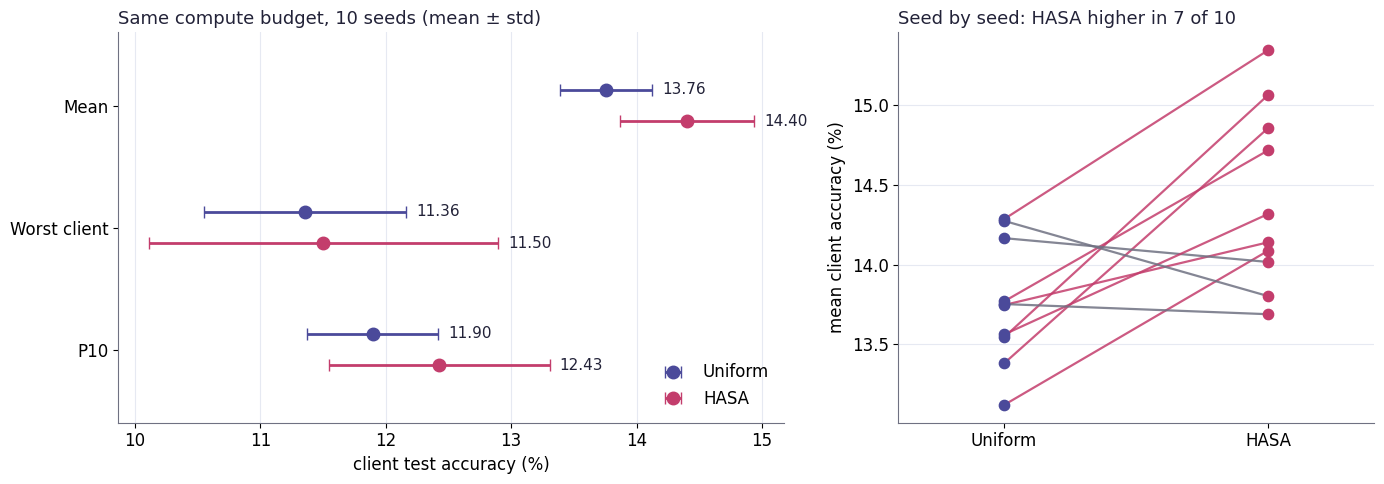

In [7]:
display(summary_table(runs))
plot_results(runs, SEEDS)

## 8. Which clients gain?

The same comparison for every client, averaged over the seeds.

,HASA width (%),Uniform (%),HASA (%),gain (pp)
client,,,,
The Startup,29.2,13.34 ± 0.32,13.91 ± 0.28,0.57
Towards Data Science,73.1,15.11 ± 0.77,17.02 ± 0.58,1.91
Data Driven Investor,43.8,12.15 ± 0.72,12.75 ± 0.60,0.60
UX Collective,80.0,11.99 ± 0.92,13.96 ± 0.95,1.97
The Writing Cooperative,80.0,15.99 ± 0.79,15.51 ± 0.55,-0.48
Better Marketing,58.4,13.72 ± 1.32,14.58 ± 1.06,0.86
Better Humans,80.0,14.00 ± 2.31,13.09 ± 3.02,-0.91


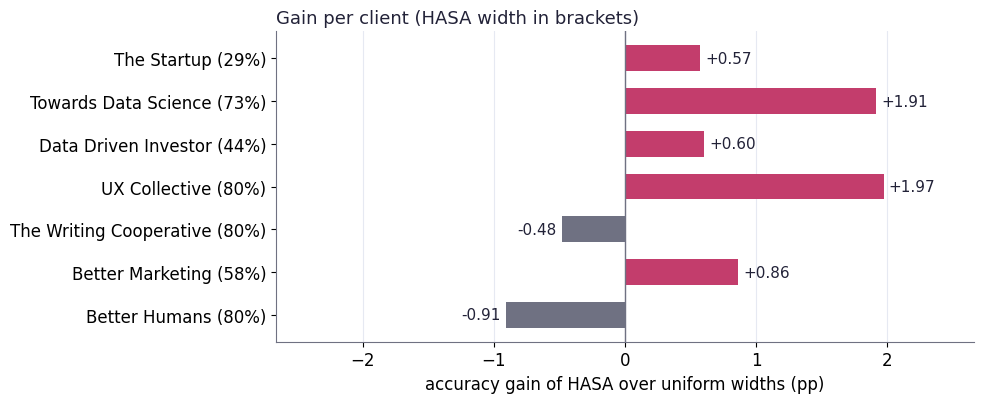

In [8]:
per_client = per_client_table(runs, bench.client_names, r)
display(per_client)
plot_client_gains(per_client)

## Try it yourself

- Flip the direction and give the wide subnets to the least heterogeneous clients: `run_policy(bench, scores, "difficulty_only", device, seed=42, invert_difficulty=True)`.
- Allocate by data size instead (`"size_only"`), or by a mix of size and heterogeneity (`"mixed"`).
- Every run keeps its history every fifth round, for example `runs["HASA"][0]["test_mean"]`.